# 10 · VEOC mission control dashboard

**Mission.** Explore a full-screen OSIRIS-inspired coordination workspace and reproduce its evidence-led analysis in Python.

![Illustrated OSIRIS VEOC mission board](assets/veoc-splash.svg)

> **Exercise only.** All sectors, calls, flood depths, beds, and travel times below are invented. Run each notebook independently with the **Python (Pyodide)** kernel in JupyterLite. First startup downloads the browser runtime. The linked OSIRIS console is a separate application.

[Book home](intro.md) Â· [2D operations map](https://jltobias.github.io/JupyterLite-Osiris/scenes/operations-2d.html) Â· [3D scene](https://jltobias.github.io/JupyterLite-Osiris/scenes/operations-3d.html) Â· [OSIRIS](https://osirisai.live/)

In [1]:
import math, json, statistics
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
SECTORS = [
 {"name":"Harbor", "lat":29.93,"lon":-90.07,"population":18000,"calls":34,"flood_m":0.9,"open_beds":12,"road_min":28,"reporting":0.84},
 {"name":"Eastbank","lat":29.96,"lon":-90.00,"population":24000,"calls":22,"flood_m":0.4,"open_beds":24,"road_min":19,"reporting":0.91},
 {"name":"Canal",   "lat":29.98,"lon":-90.10,"population":12000,"calls":31,"flood_m":1.4,"open_beds":4, "road_min":42,"reporting":0.68},
 {"name":"North",   "lat":30.05,"lon":-90.07,"population":30000,"calls":18,"flood_m":0.1,"open_beds":38,"road_min":14,"reporting":0.96},
 {"name":"Bayou",   "lat":29.89,"lon":-90.12,"population":9000, "calls":25,"flood_m":1.1,"open_beds":7, "road_min":51,"reporting":0.72},
 {"name":"Airport", "lat":30.00,"lon":-90.25,"population":16000,"calls":11,"flood_m":0.2,"open_beds":18,"road_min":23,"reporting":0.89},
]
for sector in SECTORS:
    sector["rate_10k"] = sector["calls"] / sector["population"] * 10000
print("EXERCISE DATA â€” fictional sectors, observations and facilities; no real incident implied")

EXERCISE DATA â€” fictional sectors, observations and facilities; no real incident implied


## Launch the visual command center
[**Open the full-screen VEOC dashboard →**](https://jltobias.github.io/JupyterLite-Osiris/scenes/veoc-dashboard.html)

The dashboard combines a time scrubber, seven switchable exercise overlays, a selectable 2D map and rotatable 3D globe, demand and reporting trends, sector comparison, priority ranking, an evidence desk, sixteen OSIRIS capability cards, GeoJSON export, and a situation-report preview. It runs as a standalone static page with original code and **fictional exercise data**. It does not call OSIRIS or provider APIs. Open [live OSIRIS](https://osirisai.live/) separately to compare how its actual layers behave.

The embedded dashboard below may be constrained by a notebook viewer. Use the full-screen link for the complete interaction.

In [2]:
from IPython.display import IFrame
dashboard_url = "https://jltobias.github.io/JupyterLite-Osiris/scenes/veoc-dashboard.html"
display(IFrame(src=dashboard_url,width='100%',height=920))

## Reproduce the desk calculations
The dashboard uses a transparent four-term exercise priority score: assistance-call rate (35%), modeled flood depth (30%), assumed road time (20%), and reporting gap (15%). Change `hour` below to compare conditions. The score is a conversation aid, not an automated dispatch rule.

In [3]:
hour = 4  # Set an exercise hour from 0 to 12.
assert 0 <= hour <= 12
state=[]
for s in SECTORS:
    row=s.copy()
    row['calls']=round(s['calls']*(.68+.08*hour))
    row['flood_m']=round(s['flood_m']*(.60+.10*hour),2)
    row['reporting']=min(1,s['reporting']*(.85+.0375*hour))
    row['rate_10k']=row['calls']/row['population']*10000
    row['score']=(.35*min(row['rate_10k']/30,1)+.30*min(row['flood_m']/1.5,1)
                  +.20*min(row['road_min']/60,1)+.15*(1-row['reporting']))
    state.append(row)
print(f"EXERCISE T+{hour} h · {sum(s['calls'] for s in state)} fictional assistance calls")
for rank,s in enumerate(sorted(state,key=lambda s:s['score'],reverse=True),1):
    print(f"{rank}. {s['name']:8} score {s['score']:.3f} · {s['calls']:2} calls · {s['flood_m']:.1f} m modeled depth")

EXERCISE T+4 h · 141 fictional assistance calls
1. Canal    score 0.769 · 31 calls · 1.4 m modeled depth
2. Bayou    score 0.756 · 25 calls · 1.1 m modeled depth
3. Harbor   score 0.518 · 34 calls · 0.9 m modeled depth
4. Eastbank score 0.264 · 22 calls · 0.4 m modeled depth
5. Airport  score 0.213 · 11 calls · 0.2 m modeled depth
6. North    score 0.143 · 18 calls · 0.1 m modeled depth


## The map, trend, and pressure dashboard
Each panel answers a different operational question. The map asks **where**; the trend asks **when**; the sector chart asks **relative to what denominator**; the priority chart asks **under which assumptions**. Review all four before writing a headline.

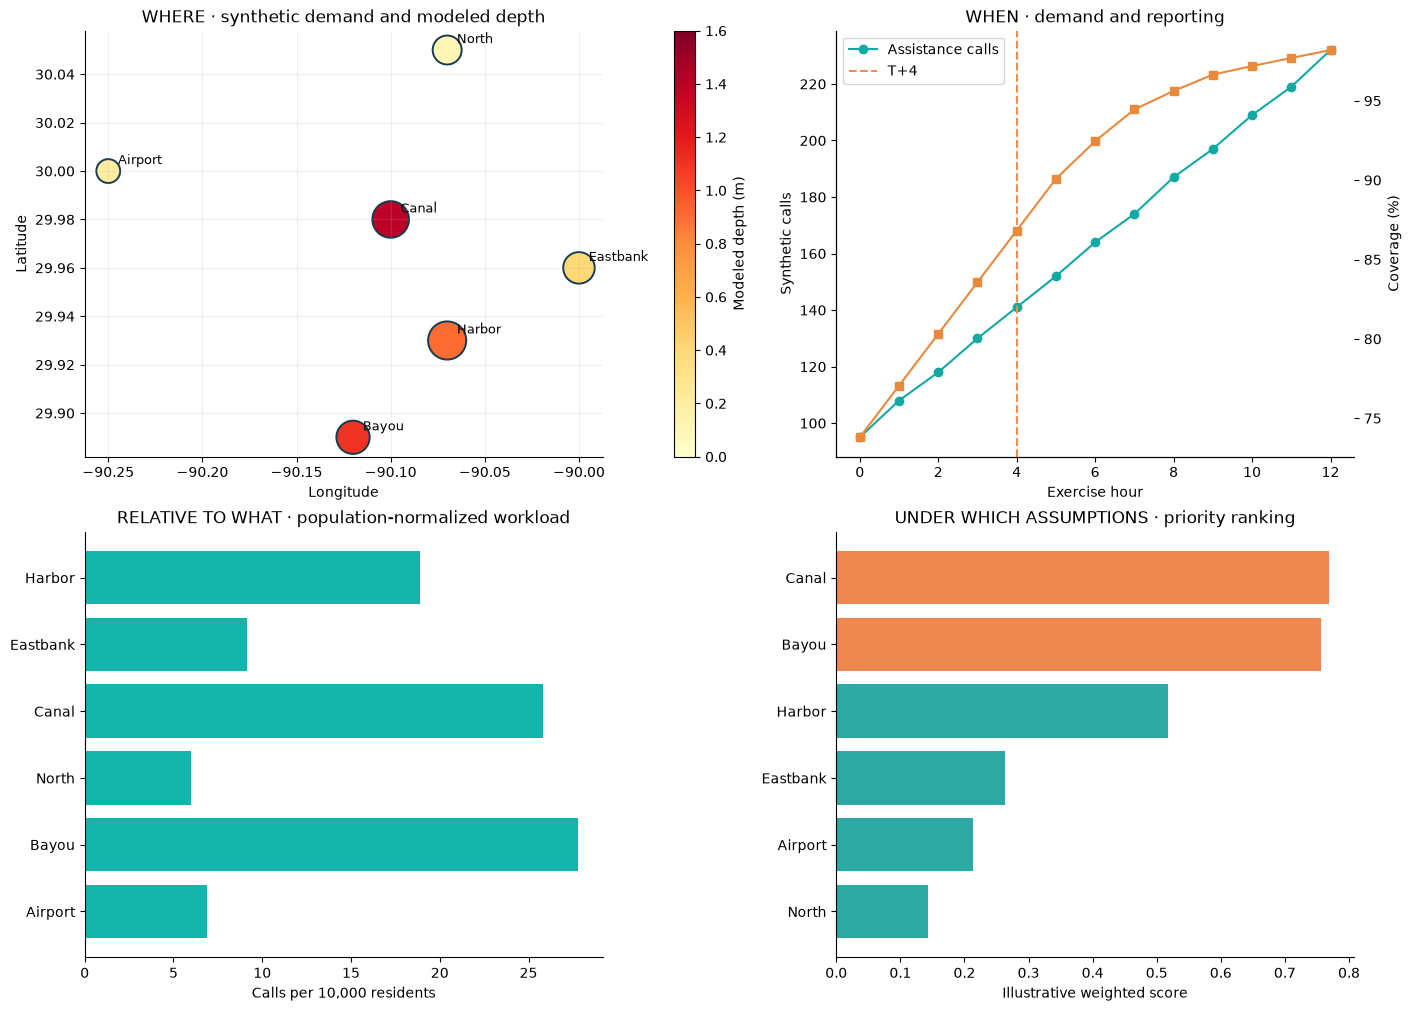

In [4]:
fig,axs=plt.subplots(2,2,figsize=(14,10),layout='constrained')
ax=axs[0,0]
sizes=[75+s['calls']*20 for s in state]
sc=ax.scatter([s['lon'] for s in state],[s['lat'] for s in state],s=sizes,c=[s['flood_m'] for s in state],cmap='YlOrRd',vmin=0,vmax=1.6,edgecolor='#173b51',linewidth=1.4)
for s in state: ax.annotate(s['name'],(s['lon'],s['lat']),xytext=(7,5),textcoords='offset points',fontsize=9)
ax.set(xlabel='Longitude',ylabel='Latitude',title='WHERE · synthetic demand and modeled depth');ax.grid(alpha=.2);fig.colorbar(sc,ax=ax,label='Modeled depth (m)')
hours=np.arange(13)
totals=[sum(round(s['calls']*(.68+.08*h)) for s in SECTORS) for h in hours]
coverage=[sum(min(1,s['reporting']*(.85+.0375*h))*s['population'] for s in SECTORS)/sum(s['population'] for s in SECTORS)*100 for h in hours]
ax=axs[0,1];ax.plot(hours,totals,'o-',color='#12a9a4',label='Assistance calls');ax.axvline(hour,color='#f28c50',ls='--',label=f'T+{hour}');ax.set(xlabel='Exercise hour',ylabel='Synthetic calls',title='WHEN · demand and reporting');ax2=ax.twinx();ax2.plot(hours,coverage,'s-',color='#e8893c',label='Reporting coverage');ax2.set_ylabel('Coverage (%)');ax.legend(loc='upper left')
names=[s['name'] for s in state];ax=axs[1,0];ax.barh(names,[s['rate_10k'] for s in state],color='#14b4aa');ax.invert_yaxis();ax.set(xlabel='Calls per 10,000 residents',title='RELATIVE TO WHAT · population-normalized workload')
ranked=sorted(state,key=lambda s:s['score'],reverse=True);ax=axs[1,1];ax.barh([s['name'] for s in ranked],[s['score'] for s in ranked],color=['#ee8750' if i<2 else '#2da9a4' for i in range(len(ranked))]);ax.invert_yaxis();ax.set(xlabel='Illustrative weighted score',title='UNDER WHICH ASSUMPTIONS · priority ranking')
plt.show()

## Evidence and handover
The map and charts contain no verified facts. A live VEOC would need a timestamped source record, alternate corroboration, owner, and review state for each claim. Cameras cannot establish conditions outside their view; an aircraft marker cannot establish a relief mission; a port marker cannot establish a live vessel position. The [upstream OSIRIS README](https://github.com/simplifaisoul/osiris#readme) describes its layers and specialist features. [NOAA GOES imagery](https://www.star.nesdis.noaa.gov/GOES/) and [OSIRIS broadcast/camera views](https://osirisai.live/) are external visual sources with their own provenance and rights.

In [5]:
evidence_packet={
    'scenario':'FICTIONAL COASTAL STORM / EDUCATIONAL EXERCISE',
    'exercise_hour':hour,
    'observed':[],
    'modeled':['Flood depth','Road travel time','Assistance-call trajectory'],
    'unverified':['Camera leads','Clinic bed counts','Road closure lead'],
    'priority_for_verification':[s['name'] for s in ranked[:2]],
    'next_actions':['Call field liaison for road status','Confirm facility capacity','Check original provider timestamps'],
    'source':'https://github.com/jltobias/JupyterLite-Osiris'
}
display(Markdown('### Exercise handover packet\n```json\n'+json.dumps(evidence_packet,indent=2)+'\n```'))

### Exercise handover packet
```json
{
  "scenario": "FICTIONAL COASTAL STORM / EDUCATIONAL EXERCISE",
  "exercise_hour": 4,
  "observed": [],
  "modeled": [
    "Flood depth",
    "Road travel time",
    "Assistance-call trajectory"
  ],
  "unverified": [
    "Camera leads",
    "Clinic bed counts",
    "Road closure lead"
  ],
  "priority_for_verification": [
    "Canal",
    "Bayou"
  ],
  "next_actions": [
    "Call field liaison for road status",
    "Confirm facility capacity",
    "Check original provider timestamps"
  ],
  "source": "https://github.com/jltobias/JupyterLite-Osiris"
}
```

## Continue into the real cockpit
The capability wall points to live or authoritative context for earthquakes, fire, weather, aviation, maritime references, public cameras, broadcasts, space weather, cyber/CVE information, sanctions, and OI Assist/Forecast. OSIRIS documents these domains, but some functions depend on credentials, backend services, or source availability. A dashboard card is an invitation to investigate, not proof that a live feed was loaded. For a working VEOC, add authentication, incident logging, data-quality monitoring, operational roles, and official alerting under local incident-command procedures.

## Field exercise and review
1. Scrub the dashboard from T+0 to T+12 and identify when the top two sectors exchange rank. Explain why their scores change. 2. Toggle off flood depth and explain what the map hides. 3. Inspect one camera lead and state what must be checked at the operator. 4. Download the GeoJSON and situation report, then rewrite the report with observed, modeled, and unknown headings. 5. Name one OSIRIS capability that requires special authorization or provider terms.

## Source desk
- [OSIRIS source and MIT license](https://github.com/simplifaisoul/osiris) Â· [OSIRIS live console](https://osirisai.live/)
- [USGS Earthquake API](https://earthquake.usgs.gov/fdsnws/event/1/) Â· [NASA EONET](https://eonet.gsfc.nasa.gov/docs/v3) Â· [NASA FIRMS](https://firms.modaps.eosdis.nasa.gov/)
- [NOAA National Hurricane Center](https://www.nhc.noaa.gov/) Â· [GDACS](https://www.gdacs.org/) Â· [OpenSky Network](https://opensky-network.org/)

**Use rule:** A source link provides context, not independent confirmation of this fictional exercise. Check timestamps, geography, provider terms, and incident command procedures before any real decision.